# Lab 9

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Questions

#### 1. Write a python function program to demonstrate the working of the decision tree based C4.5 algorithms without using ```scikit-learn``` library. Use following data set for building the decision tree and apply this knowledge to classify a new sample. The dataset has three attributes: Outlook (Sunny, Overcast, Rainy), Temperature, Humidity and Wind (Weak, Strong). The target attribute is Play Tennis (Yes/No).

In [43]:
data = {
    "Outlook": [
        "Sunny", "Sunny", "Overcast", "Rain", "Rain", "Rain",
        "Overcast", "Sunny", "Sunny", "Rain", "Sunny",
        "Overcast", "Overcast", "Rain"
    ],
    
    "Temperature": [
        85, 80, 83, 70, 68, 65,
        64, 72, 69, 75, 75,
        72, 81, 71
    ],
    
    "Humidity": [
        85, 90, 78, 96, 80, 70,
        65, 95, 70, 80, 70,
        90, 75, 80
    ],
    
    "Wind": [
        "Weak", "Strong", "Weak", "Weak", "Weak", "Strong",
        "Strong", "Weak", "Weak", "Weak", "Strong",
        "Strong", "Weak", "Strong"
    ],
    
    "PlayTennis": [
        "No", "No", "Yes", "Yes", "Yes", "No",
        "Yes", "No", "Yes", "Yes", "Yes",
        "Yes", "Yes", "No"
    ]
}

df = pd.DataFrame(data)
df.to_csv("tennis.csv", index=False)

In [44]:
df = pd.read_csv("tennis.csv")
df.head()

,Outlook,Temperature,Humidity,Wind,PlayTennis
0,Sunny,85,85,Weak,No
1,Sunny,80,90,Strong,No
2,Overcast,83,78,Weak,Yes
3,Rain,70,96,Weak,Yes
4,Rain,68,80,Weak,Yes


In [45]:
import math

def entropy(df, target="PlayTennis"):    
    counts = df[target].value_counts()
    total = len(data)
    
    ent = 0
    
    for count in counts:
        p = count / total
        ent -= p * math.log2(p)
    
    return ent

In [46]:
entropy(df)

-1.5263944317989102

In [47]:
def split_information(groups, total):
    split_info = 0
    
    for group in groups:
        if len(group) == 0:
            continue
        
        p = len(group) / total
        split_info -= p * math.log2(p)
    
    return split_info

In [48]:
def gain_ratio_categorical(df, attribute):
    parent_entropy = entropy(df)
    
    weighted_entropy = 0
    groups = []
    
    for value in df[attribute].unique():
        subset = df[df[attribute] == value]
        groups.append(subset)
        
        weighted_entropy += (
            len(subset) / len(df)
        ) * entropy(subset)
    
    information_gain = parent_entropy - weighted_entropy
    
    split_info = split_information(
        groups,
        len(df)
    )
    
    if split_info == 0:
        return 0
    
    gain_ratio = information_gain / split_info
    
    return gain_ratio

In [49]:
print(f"Gain Ratio of Outlook: {gain_ratio_categorical(df, 'Outlook')}")
print(f"Gain Ratio of Wind: {gain_ratio_categorical(df, 'Wind')}")

Gain Ratio of Outlook: -1.453978065241085
Gain Ratio of Wind: -2.057588266166515


In [50]:
def gain_ratio_numerical(df, attribute):
    values = sorted(df[attribute].unique())
    
    best_gain_ratio = -1
    best_threshold = None
    
    thresholds = []
    
    for i in range(len(values) - 1):
        threshold = (values[i] + values[i + 1]) / 2
        thresholds.append(threshold)
    
    parent_entropy = entropy(df)
    
    for threshold in thresholds:
        
        left = df[df[attribute] <= threshold]
        right = df[df[attribute] > threshold]
        
        if len(left) == 0 or len(right) == 0:
            continue
        
        weighted_entropy = (
            len(left) / len(df) * entropy(left)
            +
            len(right) / len(df) * entropy(right)
        )
        
        information_gain = parent_entropy - weighted_entropy
        
        split_info = split_information(
            [left, right],
            len(df)
        )
        
        if split_info == 0:
            continue
        
        gain_ratio = information_gain / split_info
        
        if gain_ratio > best_gain_ratio:
            best_gain_ratio = gain_ratio
            best_threshold = threshold
    
    return best_gain_ratio, best_threshold

In [51]:
temp_gain, temp_threshold = gain_ratio_numerical(df, "Temperature")
humidity_gain, humidity_threshold = gain_ratio_numerical(df, "Humidity")

print(f"Temperature: Gain Ratio: {temp_gain}")
print(f"Temperature: Best Threshold: {temp_threshold}\n")

print(f"Humidity: Gain Ratio: {humidity_gain}")
print(f"Humidity: Best Threshold: {humidity_threshold}")

Temperature: Gain Ratio: -1
Temperature: Best Threshold: None

Humidity: Gain Ratio: -1
Humidity: Best Threshold: None


In [52]:
attributes = [
    "Outlook",
    "Temperature",
    "Humidity",
    "Wind"
]

attributes_numerical = [
    "Temperature",
    "Humidity"
]

In [53]:
def find_best_split(df, available_attributes): 
    best_attribute = None
    best_gain_ratio = -1
    best_threshold = None
    
    for attribute in available_attributes:
        
        if attribute in attributes_numerical:
            gain_ratio, threshold = gain_ratio_numerical(df, attribute)
            
        else:
            gain_ratio = gain_ratio_categorical(df, attribute)
            threshold = None
        
        if gain_ratio > best_gain_ratio:
            best_gain_ratio = gain_ratio
            best_attribute = attribute
            best_threshold = threshold
    
    return best_attribute, best_gain_ratio, best_threshold

In [54]:
best_attribute, gain_ratio, threshold = find_best_split(df, attributes)

print(f"Best Attribute: {best_attribute}")
print(f"Gain Ratio: {gain_ratio}")
print(f"Threshold: {threshold}")

Best Attribute: None
Gain Ratio: -1
Threshold: None


In [55]:
def majority_class(df, target="PlayTennis"):
    return df[target].value_counts().idxmax()

In [56]:
def c45(df, available_attributes, target="PlayTennis"):
    if len(df[target].unique()) == 1:
        return df[target].iloc[0]
    
    if len(available_attributes) == 0:
        return majority_class(df)

    best_attribute, best_gain, threshold = find_best_split(df, available_attributes)
    
    if best_attribute is None:
        return majority_class(df)
    
    tree = {}
    
    if best_attribute in attributes_numerical:
        tree[best_attribute] = {
            "threshold": threshold
        }
        
        left = df[
            df[best_attribute] <= threshold
        ]
        
        right = df[
            df[best_attribute] > threshold
        ]
        
        tree[best_attribute]["<="] = c45(
            left,
            available_attributes.copy()
        )
        
        tree[best_attribute][">"] = c45(
            right,
            available_attributes.copy()
        )
    
    else:
        tree[best_attribute] = {}
        
        remaining_attributes = [
            attr for attr in available_attributes
            if attr != best_attribute
        ]
        
        for value in df[best_attribute].unique():
            subset = df[
                df[best_attribute] == value
            ]
            
            tree[best_attribute][value] = c45(
                subset,
                remaining_attributes
            )
        
    return tree

In [57]:
tree = c45(df, attributes.copy())

tree

'Yes'

In [58]:
def print_c45(tree, indent=""):
    if not isinstance(tree, dict):
        print(indent + "Prediction:", tree)
        return
    
    attribute = next(iter(tree))
    print(indent + attribute)
    node = tree[attribute]
    
    if "threshold" in node:
        threshold = node["threshold"]
        
        print(
            indent +
            f"  <= {threshold:.2f}"
        )
        
        print_c45(
            node["<="],
            indent + "      "
        )        
        
        print(
            indent +
            f"  > {threshold:.2f}"
        )
        
        print_c45(
            node[">"],
            indent + "      "
        )
    
    else:
        for value, subtree in node.items():
            print(
                indent +
                f"  {value}"
            )
            
            print_c45(
                subtree,
                indent + "      "
            )

In [59]:
print_c45(tree)

Prediction: Yes


In [60]:
def predict_c45(tree, sample):
    if not isinstance(tree, dict):
        return tree
    
    attribute = next(iter(tree))    
    node = tree[attribute]
    
    if "threshold" in node:
        threshold = node["threshold"]

        if sample[attribute] <= threshold:
            return predict_c45(node["<="], sample)
        
        else:
            return predict_c45(node[">"], sample)
    
    else:    
        value = sample[attribute]
        
        if value not in node:
            return "Unknown"
        
        return predict_c45(node[value], sample)

In [61]:
new_sample = {
    "Outlook": "Sunny",
    "Temperature": 72,
    "Humidity": 90,
    "Wind": "Weak"
}

prediction = predict_c45(tree, new_sample)

print(f"Predicted Play Tennis: {prediction}")

Predicted Play Tennis: Yes


In [62]:
for attribute in attributes:
    if attribute in attributes_numerical:
        gain_ratio, threshold = gain_ratio_numerical(df, attribute)
        
        print(
            f"{attribute:12} : "
            f"Gain Ratio = {gain_ratio:.4f}, "
            f"Threshold = {threshold}"
        )
    
    else:
        gain_ratio = gain_ratio_categorical(df, attribute)
        
        print(
            f"{attribute:12} : "
            f"Gain Ratio = {gain_ratio:.4f}"
        )

Outlook      : Gain Ratio = -1.4540
Temperature  : Gain Ratio = -1.0000, Threshold = None
Humidity     : Gain Ratio = -1.0000, Threshold = None
Wind         : Gain Ratio = -2.0576


#### 2. Write a python function program to demonstrate the working of the decision tree based CART algorithms without using ```scikit-learn``` library. Use Q. No. 1 data set for building the decision tree and apply this knowledge to classify a new sample. The dataset has three attributes: Outlook (Sunny, Overcast, Rainy), Temperature, Humidity and Wind (Weak, Strong). The target attribute is Play Tennis (Yes/No).

In [63]:
df = pd.read_csv("tennis.csv")
df.head()

,Outlook,Temperature,Humidity,Wind,PlayTennis
0,Sunny,85,85,Weak,No
1,Sunny,80,90,Strong,No
2,Overcast,83,78,Weak,Yes
3,Rain,70,96,Weak,Yes
4,Rain,68,80,Weak,Yes


In [64]:
def gini(df, target="PlayTennis"):
    counts = df[target].value_counts()
    total = len(df)

    impurity = 1

    for count in counts:
        p = count / total
        impurity -= p ** 2

    return impurity

In [65]:
gini(df)

0.4591836734693877

In [66]:
def weighted_gini(left, right):
    total = len(left) + len(right)

    gini_split = (
        (len(left) / total) * gini(left)
        +
        (len(right) / total) * gini(right)
    )

    return gini_split

In [67]:
def best_split_numerical(df, attribute):
    values = sorted(df[attribute].unique())

    best_gini = float("inf")
    best_threshold = None

    for i in range(len(values) - 1):
        threshold = (values[i] + values[i + 1]) / 2

        left = df[df[attribute] <= threshold]
        right = df[df[attribute] > threshold]

        if len(left) == 0 or len(right) == 0:
            continue

        split_gini = weighted_gini(left, right)

        if split_gini < best_gini:
            best_gini = split_gini
            best_threshold = threshold

    return best_gini, best_threshold

In [68]:
temp_gini, temp_threshold = best_split_numerical(df, "Temperature")
humidity_gini, humidity_threshold = best_split_numerical(df, "Humidity")

print(f"Temperature: Best Gini: {temp_gini}")
print(f"Temperature: Best Threshold: {temp_threshold}\n")

print(f"Humidity: Best Gini: {humidity_gini}")
print(f"Humidity: Best Threshold: {humidity_threshold}")

Temperature: Best Gini: 0.3956043956043956
Temperature: Best Threshold: 84.0

Humidity: Best Gini: 0.3936507936507937
Humidity: Best Threshold: 82.5


In [69]:
def best_split_categorical(df, attribute):
    values = df[attribute].unique()

    best_gini = float("inf")
    best_value = None

    for value in values:
        left = df[df[attribute] == value]
        right = df[df[attribute] != value]

        if len(left) == 0 or len(right) == 0:
            continue

        split_gini = weighted_gini(left, right)

        if split_gini < best_gini:
            best_gini = split_gini
            best_value = value

    return best_gini, best_value

In [70]:
outlook_gini, outlook_value = best_split_categorical(df, "Outlook")
wind_gini, wind_value = best_split_categorical(df, "Wind")

print(f"Outlook: Best Gini: {outlook_gini}")
print(f"Outlook: Best Split Value: {outlook_value}\n")

print(f"Wind: Best Gini: {wind_gini}")
print(f"Wind: Best Split Value: {wind_value}")

Outlook: Best Gini: 0.35714285714285715
Outlook: Best Split Value: Overcast

Wind: Best Gini: 0.42857142857142855
Wind: Best Split Value: Weak


In [71]:
attributes = [
    "Outlook",
    "Temperature",
    "Humidity",
    "Wind"
]

attributes_numerical = [
    "Temperature",
    "Humidity"
]

In [72]:
def find_best_split(df):
    best_attribute = None
    best_value = None
    best_gini = float("inf")
    best_type = None

    for attribute in attributes:
        if attribute in attributes_numerical:
            split_gini, threshold = best_split_numerical(df, attribute)

            if split_gini < best_gini:
                best_gini = split_gini
                best_attribute = attribute
                best_value = threshold
                best_type = "numeric"

        else:
            split_gini, value = best_split_categorical(df, attribute)

            if split_gini < best_gini:
                best_gini = split_gini
                best_attribute = attribute
                best_value = value
                best_type = "categorical"

    return best_attribute, best_value, best_gini, best_type

In [73]:
best_attribute, split_value, gini_split, split_type = find_best_split(df)

print(f"Best Attribute: {best_attribute}")
print(f"Split Value: {split_value}")
print(f"Gini after split: {gini_split}")
print(f"Split Type: {split_type}")

Best Attribute: Outlook
Split Value: Overcast
Gini after split: 0.35714285714285715
Split Type: categorical


In [74]:
def cart(df, depth=0, max_depth=10, target="PlayTennis"):
    if len(df[target].unique()) == 1:
        return df[target].iloc[0]

    if depth >= max_depth:
        return majority_class(df)

    attribute, value, split_gini, split_type = find_best_split(df)

    if attribute is None:
        return majority_class(df)

    if split_gini >= gini(df):
        return majority_class(df)

    tree = {
        "attribute": attribute,
        "value": value,
        "type": split_type
    }

    if split_type == "numeric":
        left = df[df[attribute] <= value]
        right = df[df[attribute] > value]

    else:
        left = df[df[attribute] == value]
        right = df[df[attribute] != value]

    if len(left) == 0 or len(right) == 0:
        return majority_class(df)

    tree["left"] = cart(left, depth + 1, max_depth)
    tree["right"] = cart(right, depth + 1, max_depth)

    return tree

In [75]:
tree = cart(df)
tree

{'attribute': 'Outlook',
 'value': 'Overcast',
 'type': 'categorical',
 'left': 'Yes',
 'right': {'attribute': 'Temperature',
  'value': np.float64(77.5),
  'type': 'numeric',
  'left': {'attribute': 'Temperature',
   'value': np.float64(66.5),
   'type': 'numeric',
   'left': 'No',
   'right': {'attribute': 'Temperature',
    'value': np.float64(70.5),
    'type': 'numeric',
    'left': 'Yes',
    'right': {'attribute': 'Temperature',
     'value': np.float64(73.5),
     'type': 'numeric',
     'left': 'No',
     'right': 'Yes'}}},
  'right': 'No'}}

In [76]:
def print_cart(tree, indent=""):
    if not isinstance(tree, dict):
        print(indent + "Prediction:", tree)
        return

    attribute = tree["attribute"]
    value = tree["value"]

    if tree["type"] == "numeric":
        print(indent + f"{attribute} <= {value:.2f}")

        print(indent + "  True:")
        print_cart(
            tree["left"],
            indent + "    "
        )

        print(indent + "  False:")
        print_cart(
            tree["right"],
            indent + "    "
        )

    else:
        print(indent + f"{attribute} == {value}")

        print(indent + "  True:")
        print_cart(
            tree["left"],
            indent + "    "
        )

        print(indent + "  False:")
        print_cart(
            tree["right"],
            indent + "    "
        )

In [77]:
print_cart(tree)

Outlook == Overcast
  True:
    Prediction: Yes
  False:
    Temperature <= 77.50
      True:
        Temperature <= 66.50
          True:
            Prediction: No
          False:
            Temperature <= 70.50
              True:
                Prediction: Yes
              False:
                Temperature <= 73.50
                  True:
                    Prediction: No
                  False:
                    Prediction: Yes
      False:
        Prediction: No


In [78]:
def predict_cart(tree, sample):
    if not isinstance(tree, dict):
        return tree

    attribute = tree["attribute"]
    value = tree["value"]

    if tree["type"] == "numeric":
        if sample[attribute] <= value:
            return predict_cart(tree["left"], sample)

        else:
            return predict_cart(tree["right"], sample)

    else:
        if sample[attribute] == value:
            return predict_cart(tree["left"], sample)

        else:
            return predict_cart(tree["right"], sample)

In [79]:
prediction = predict_cart(tree, new_sample)
print(f"Predicted Play Tennis: {prediction}")

Predicted Play Tennis: No


In [80]:
for attribute in attributes:
    if attribute in attributes_numerical:
        split_gini, threshold = best_split_numerical(df, attribute)

        print(
            f"{attribute:12} : "
            f"Gini = {split_gini:.4f}, "
            f"Threshold = {threshold}"
        )

    else:
        split_gini, value = best_split_categorical(df, attribute)

        print(
            f"{attribute:12} : "
            f"Gini = {split_gini:.4f}, "
            f"Split = {attribute} == {value}"
        )

Outlook      : Gini = 0.3571, Split = Outlook == Overcast
Temperature  : Gini = 0.3956, Threshold = 84.0
Humidity     : Gini = 0.3937, Threshold = 82.5
Wind         : Gini = 0.4286, Split = Wind == Weak


#### 3. Write a python function program to demonstrate the working of the decision tree based C4.5 and CART algorithms without and with using ```scikit-learn``` library. Using the following dataset, apply aforementioned algorithms. The attributes are Income (Low, Medium, High) and Credit (Good, Bad), and the target is Loan Approved (Yes/No).

In [81]:
data = {
    "Income": [
        "Low",
        "Low",
        "Medium",
        "Medium",
        "High",
        "High"
    ],
    
    "Credit": [
        "Good",
        "Bad",
        "Good",
        "Bad",
        "Good",
        "Bad"
    ],
    
    "LoanApproved": [
        "Yes",
        "No",
        "Yes",
        "Yes",
        "Yes",
        "No"
    ]
}

df = pd.DataFrame(data)
df.to_csv("loan.csv", index=False)

In [82]:
df = pd.read_csv("loan.csv")
df.head()

,Income,Credit,LoanApproved
0,Low,Good,Yes
1,Low,Bad,No
2,Medium,Good,Yes
3,Medium,Bad,Yes
4,High,Good,Yes


##### a. C4.5 without ```scikit-learn```

In [83]:
def entropy(df, target="LoanApproved"):
    counts = df[target].value_counts()
    total = len(df)

    ent = 0

    for count in counts:
        p = count / total
        ent -= p * math.log2(p)

    return ent

In [84]:
entropy(df)

0.9182958340544896

In [85]:
def gain_ratio(df, attribute):
    parent_entropy = entropy(df)

    weighted_entropy = 0
    split_info = 0

    for value in df[attribute].unique():
        subset = df[df[attribute] == value]

        p = len(subset) / len(df)

        weighted_entropy += p * entropy(subset)

        split_info -= p * math.log2(p)

    information_gain = parent_entropy - weighted_entropy

    if split_info == 0:
        return 0

    return information_gain / split_info

In [86]:
print(f"Income: Gain Ratio: {gain_ratio(df, 'Income')}")
print(f"Credit: Gain Ratio: {gain_ratio(df, 'Credit')}")

Income: Gain Ratio: 0.15876032857139014
Credit: Gain Ratio: 0.4591479170272448


In [87]:
attributes = [
    "Income",
    "Credit"
]

In [88]:
def best_attribute_c45(df, attributes):

    best_attr = None
    best_gain = -1

    for attribute in attributes:
        gr = gain_ratio(df, attribute)

        if gr > best_gain:
            best_gain = gr
            best_attr = attribute

    return best_attr

In [89]:
def majority_class(data):
    return data["LoanApproved"].value_counts().idxmax()

In [90]:
def c45(df, attributes, target="LoanApproved"):
    target_values = df[target].unique()

    if len(target_values) == 1:
        return target_values[0]

    if len(attributes) == 0:
        return majority_class(df)

    best_attr = best_attribute_c45(df, attributes)

    tree = {
        best_attr: {}
    }

    remaining_attributes = [
        attr
        for attr in attributes
        if attr != best_attr
    ]

    for value in df[best_attr].unique():
        subset = df[df[best_attr] == value]

        tree[best_attr][value] = c45(
            subset,
            remaining_attributes
        )

    return tree

In [91]:
tree = c45(df, attributes.copy())
tree

{'Credit': {'Good': 'Yes',
  'Bad': {'Income': {'Low': 'No', 'Medium': 'Yes', 'High': 'No'}}}}

In [92]:
def print_c45(tree, indent=""):
    if not isinstance(tree, dict):
        print(indent + "Prediction:", tree)
        return

    attribute = next(iter(tree))

    print(indent + attribute)

    for value, subtree in tree[attribute].items():
        print(
            indent +
            f"  {value}"
        )

        print_c45(
            subtree,
            indent + "    "
        )

In [93]:
print_c45(tree)

Credit
  Good
    Prediction: Yes
  Bad
    Income
      Low
        Prediction: No
      Medium
        Prediction: Yes
      High
        Prediction: No


In [94]:
def predict_c45(tree, sample):
    if not isinstance(tree, dict):
        return tree

    attribute = next(iter(tree))

    value = sample[attribute]

    if value not in tree[attribute]:
        return "Unknown"

    return predict_c45(
        tree[attribute][value],
        sample
    )

In [95]:
new_sample = {
    "Income": "Low",
    "Credit": "Good"
}

prediction = predict_c45(tree, new_sample)
print(f"Predicted Loan Approved: {prediction}")

Predicted Loan Approved: Yes


##### b. CART without ```scikit-learn```

In [96]:
def gini(df, target="LoanApproved"):
    counts = df[target].value_counts()
    total = len(df)
    impurity = 1

    for count in counts:
        p = count / total
        impurity -= p ** 2

    return impurity

In [97]:
gini(df)

0.4444444444444445

In [98]:
def weighted_gini(left, right):
    total = len(left) + len(right)

    return (
        len(left) / total * gini(left)
        +
        len(right) / total * gini(right)
    )

In [99]:
def best_split_categorical(df, attribute):
    best_gini = float("inf")
    best_value = None

    for value in df[attribute].unique():
        left = df[df[attribute] == value]
        right = df[df[attribute] != value]

        if len(left) == 0 or len(right) == 0:
            continue

        split_gini = weighted_gini(left, right)

        if split_gini < best_gini:
            best_gini = split_gini
            best_value = value

    return best_gini, best_value

In [100]:
income_gini, income_value = best_split_categorical(df, "Income")
credit_gini, credit_value = best_split_categorical(df, "Credit")

print(f"Income: Best Gini: {income_gini}")
print(f"Income: Best Split Value: {income_value}\n")

print(f"Credit: Best Gini: {credit_gini}")
print(f"Credit: Best Split Value: {credit_value}")

Income: Best Gini: 0.3333333333333333
Income: Best Split Value: Medium

Credit: Best Gini: 0.22222222222222224
Credit: Best Split Value: Good


In [101]:
def cart_split(df):
    attributes = [
        "Income",
        "Credit"
    ]

    best_attribute = None
    best_value = None
    best_gini = float("inf")

    for attribute in attributes:
        split_gini, value = best_split_categorical(
            df,
            attribute
        )

        if split_gini < best_gini:

            best_gini = split_gini
            best_attribute = attribute
            best_value = value

    return best_attribute, best_value, best_gini

In [102]:
def cart(df, target="LoanApproved"):
    if len(df[target].unique()) == 1:
        return df[target].iloc[0]

    attribute, value, split_gini = cart_split(df)

    if attribute is None:
        return majority_class(df)

    if split_gini >= gini(df):
        return majority_class(df)

    left = df[df[attribute] == value]
    right = df[df[attribute] != value]

    tree = {
        "attribute": attribute,
        "value": value,
        "left": cart(left),
        "right": cart(right)
    }

    return tree

In [103]:
tree = cart(df)
tree

{'attribute': 'Credit',
 'value': 'Good',
 'left': 'Yes',
 'right': {'attribute': 'Income',
  'value': 'Medium',
  'left': 'Yes',
  'right': 'No'}}

In [104]:
def print_cart(tree, indent=""):
    if not isinstance(tree, dict):
        print(
            indent +
            "Prediction: " +
            tree
        )
        return

    attribute = tree["attribute"]
    value = tree["value"]

    print(
        indent +
        f"{attribute} == {value}"
    )

    print(indent + "  True:")

    print_cart(
        tree["left"],
        indent + "    "
    )

    print(indent + "  False:")

    print_cart(
        tree["right"],
        indent + "    "
    )

In [105]:
print_cart(tree)

Credit == Good
  True:
    Prediction: Yes
  False:
    Income == Medium
      True:
        Prediction: Yes
      False:
        Prediction: No


In [106]:
def predict_cart(tree, sample):
    if not isinstance(tree, dict):
        return tree

    attribute = tree["attribute"]
    value = tree["value"]

    if sample[attribute] == value:
        return predict_cart(
            tree["left"],
            sample
        )

    else:
        return predict_cart(
            tree["right"],
            sample
        )

In [107]:
new_sample = {
    "Income": "Low",
    "Credit": "Good"
}

prediction = predict_cart(tree, new_sample)
print(f"Predicted Loan Approved: {prediction}")

Predicted Loan Approved: Yes


##### c. Using ```scikit-learn```

In [108]:
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()

income_encoder = LabelEncoder()
credit_encoder = LabelEncoder()
loan_encoder = LabelEncoder()

df_encoded["Income"] = income_encoder.fit_transform(df["Income"])
df_encoded["Credit"] = credit_encoder.fit_transform(df["Credit"])
df_encoded["LoanApproved"] = loan_encoder.fit_transform(df["LoanApproved"])

df_encoded.head()

,Income,Credit,LoanApproved
0,1,1,1
1,1,0,0
2,2,1,1
3,2,0,1
4,0,1,1


In [109]:
X = df_encoded[["Income", "Credit"]]
y = df_encoded["LoanApproved"]

##### CART with ```scikit-learn```

In [110]:
from sklearn.tree import DecisionTreeClassifier

cart_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=67
)

cart_model.fit(X, y)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",67
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [111]:
new_sample_df = pd.DataFrame({
    "Income": [
        income_encoder.transform(["Low"])[0]
    ],

    "Credit": [
        credit_encoder.transform(["Good"])[0]
    ]
})

new_sample_df

,Income,Credit
0,1,1


In [112]:
prediction = cart_model.predict(new_sample_df)
result = loan_encoder.inverse_transform(prediction)

print(f"CART Prediction: {result[0]}")

CART Prediction: Yes


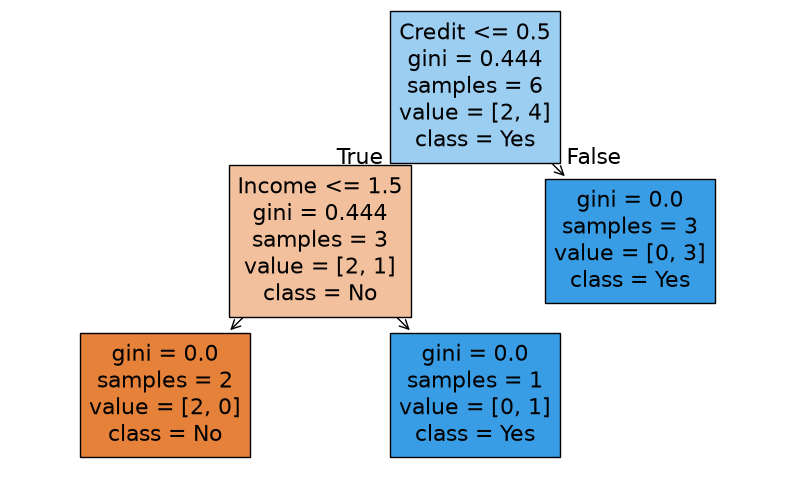

In [113]:
from sklearn.tree import plot_tree

plt.figure(
    figsize=(10, 6)
)

plot_tree(
    cart_model,
    feature_names=[
        "Income",
        "Credit"
    ],
    class_names=loan_encoder.classes_,
    filled=True
)

plt.show()

##### Entropy based tree with ```scikit-learn```

In [114]:
entropy_model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=0
)

entropy_model.fit(X, y)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [115]:
prediction = entropy_model.predict(new_sample_df)
result = loan_encoder.inverse_transform(prediction)

print(f"Entropy Tree Prediction: {result[0]}")

Entropy Tree Prediction: Yes


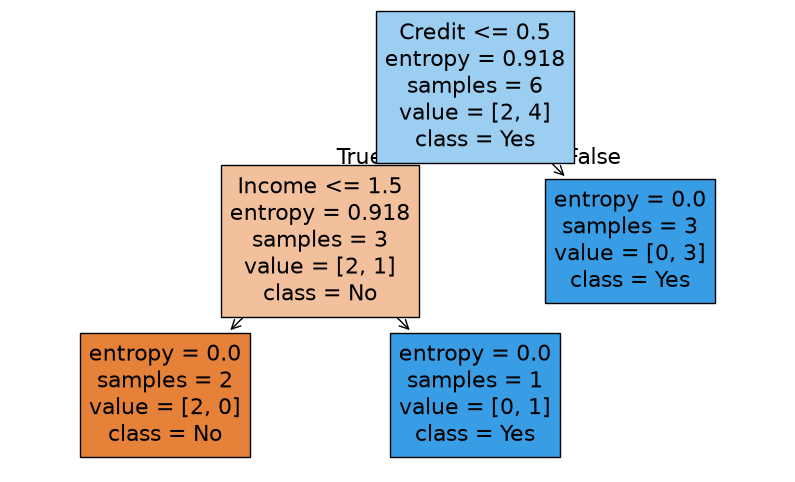

In [116]:
plt.figure(
    figsize=(10, 6)
)

plot_tree(
    entropy_model,
    feature_names=[
        "Income",
        "Credit"
    ],
    class_names=loan_encoder.classes_,
    filled=True
)

plt.show()

## Additional questions

#### 1. Write a program to demonstrate the working of the decision tree based C4.5 algorithms using ```scikit-learn``` library. Use an following data set (Q. No 1 under Questions) for building the decision tree and apply this knowledge to classify a new sample. Compare with and without using ```scikit-learn``` library, also the results. The dataset has three attributes: Outlook (Sunny, Overcast, Rainy), Temperature, Humidity and Wind (Weak, Strong). The target attribute is Play Tennis (Yes/No).

In [117]:
df = pd.read_csv("tennis.csv")
df.head()

,Outlook,Temperature,Humidity,Wind,PlayTennis
0,Sunny,85,85,Weak,No
1,Sunny,80,90,Strong,No
2,Overcast,83,78,Weak,Yes
3,Rain,70,96,Weak,Yes
4,Rain,68,80,Weak,Yes


##### C4.5 without ```scikit-learn```

In [118]:
def entropy(df, target="PlayTennis"):
    counts = df[target].value_counts()
    total = len(df)

    ent = 0

    for count in counts:
        p = count / total
        ent -= p * math.log2(p)

    return ent

In [119]:
def split_information(groups, total):
    split_info = 0

    for group in groups:
        if len(group) == 0:
            continue

        p = len(group) / total
        split_info -= p * math.log2(p)

    return split_info

In [120]:
def gain_ratio_categorical(df, attribute):
    parent_entropy = entropy(df)

    weighted_entropy = 0
    groups = []

    for value in df[attribute].unique():
        subset = df[df[attribute] == value]

        groups.append(subset)

        weighted_entropy += (
            len(subset) / len(df)
        ) * entropy(subset)

    information_gain = parent_entropy - weighted_entropy

    split_info = split_information(groups, len(df))

    if split_info == 0:
        return 0

    return information_gain / split_info

In [121]:
def gain_ratio_numerical(df, attribute):
    values = sorted(df[attribute].unique())

    best_gain_ratio = -1
    best_threshold = None

    parent_entropy = entropy(df)

    for i in range(len(values) - 1):

        threshold = (
            values[i] + values[i + 1]
        ) / 2

        left = df[df[attribute] <= threshold]
        right = df[df[attribute] > threshold]

        if len(left) == 0 or len(right) == 0:
            continue

        weighted_entropy = (
            len(left) / len(df) * entropy(left)
            +
            len(right) / len(df) * entropy(right)
        )

        information_gain = parent_entropy - weighted_entropy

        split_info = split_information([left, right], len(df))

        if split_info == 0:
            continue

        gain_ratio = information_gain / split_info

        if gain_ratio > best_gain_ratio:
            best_gain_ratio = gain_ratio
            best_threshold = threshold

    return best_gain_ratio, best_threshold

In [122]:
attributes = [
    "Outlook",
    "Temperature",
    "Humidity",
    "Wind"
]

attributes_numerical = [
    "Temperature",
    "Humidity"
]

In [123]:
def find_best_split(df, available_attributes):
    best_attribute = None
    best_gain_ratio = -1
    best_threshold = None

    for attribute in available_attributes:
        if attribute in attributes_numerical:
            gain_ratio, threshold = gain_ratio_numerical(df, attribute)

        else:
            gain_ratio = gain_ratio_categorical(df, attribute)
            threshold = None

        if gain_ratio > best_gain_ratio:
            best_gain_ratio = gain_ratio
            best_attribute = attribute
            best_threshold = threshold

    return best_attribute, best_gain_ratio, best_threshold

In [124]:
def majority_class(df, target="PlayTennis"):
    return df[target].value_counts().idxmax()

In [125]:
def c45(df, available_attributes, target="PlayTennis"):
    if len(df[target].unique()) == 1:
        return df[target].iloc[0]

    if len(available_attributes) == 0:
        return majority_class(df)

    best_attribute, gain, threshold = find_best_split(df, available_attributes)

    if best_attribute is None:
        return majority_class(df)

    tree = {}

    if best_attribute in attributes_numerical:
        tree[best_attribute] = {
            "threshold": threshold
        }

        left = df[
            df[best_attribute] <= threshold
        ]

        right = df[
            df[best_attribute] > threshold
        ]

        tree[best_attribute]["<="] = c45(
            left,
            available_attributes.copy()
        )

        tree[best_attribute][">"] = c45(
            right,
            available_attributes.copy()
        )

    else:
        tree[best_attribute] = {}

        remaining = [
            attr
            for attr in available_attributes
            if attr != best_attribute
        ]

        for value in df[
            best_attribute
        ].unique():

            subset = df[
                df[best_attribute] == value
            ]

            tree[best_attribute][value] = c45(
                subset,
                remaining
            )

    return tree

In [126]:
tree = c45(df, attributes.copy())
tree

{'Temperature': {'threshold': np.float64(84.0),
  '<=': {'Temperature': {'threshold': np.float64(80.5),
    '<=': {'Temperature': {'threshold': np.float64(77.5),
      '<=': {'Temperature': {'threshold': np.float64(73.5),
        '<=': {'Temperature': {'threshold': np.float64(64.5),
          '<=': 'Yes',
          '>': {'Temperature': {'threshold': np.float64(66.5),
            '<=': 'No',
            '>': {'Temperature': {'threshold': np.float64(70.5),
              '<=': 'Yes',
              '>': {'Outlook': {'Sunny': 'No',
                'Overcast': 'Yes',
                'Rain': 'No'}}}}}}}},
        '>': 'Yes'}},
      '>': 'No'}},
    '>': 'Yes'}},
  '>': 'No'}}

In [127]:
def predict_c45(tree, sample):
    if not isinstance(tree, dict):
        return tree

    attribute = next(iter(tree))
    node = tree[attribute]

    if "threshold" in node:
        threshold = node["threshold"]

        if sample[attribute] <= threshold:
            return predict_c45(
                node["<="],
                sample
            )

        else:
            return predict_c45(
                node[">"],
                sample
            )

    else:
        value = sample[attribute]

        return predict_c45(
            node[value],
            sample
        )

In [128]:
new_sample = {
    "Outlook": "Sunny",
    "Temperature": 72,
    "Humidity": 90,
    "Wind": "Weak"
}

manual_prediction = predict_c45(tree, new_sample)
print(f"Prediction (Manual C4.5): {manual_prediction}")

Prediction (Manual C4.5): No


##### C4.5 using ```scikit-learn```

In [129]:
X = df[
    [
        "Outlook",
        "Temperature",
        "Humidity",
        "Wind"
    ]
]

y = df["PlayTennis"]

In [130]:
categorical_features = [
    "Outlook",
    "Wind"
]

numerical_features = [
    "Temperature",
    "Humidity"
]

In [131]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ],
    remainder="passthrough"
)

In [132]:
from sklearn.pipeline import Pipeline

model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),

        (
            "classifier",
            DecisionTreeClassifier(
                criterion="entropy",
                random_state=0
            )
        )
    ]
)

model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['Outlook','Temperature','Humidity','Wind']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not 

In [133]:
new_sample_df = pd.DataFrame([new_sample])
new_sample_df

,Outlook,Temperature,Humidity,Wind
0,Sunny,72,90,Weak


In [134]:
sklearn_prediction = model.predict(new_sample_df)[0]
print(f"Prediction (sklearn C4.5): {sklearn_prediction}")

Prediction (sklearn C4.5): No


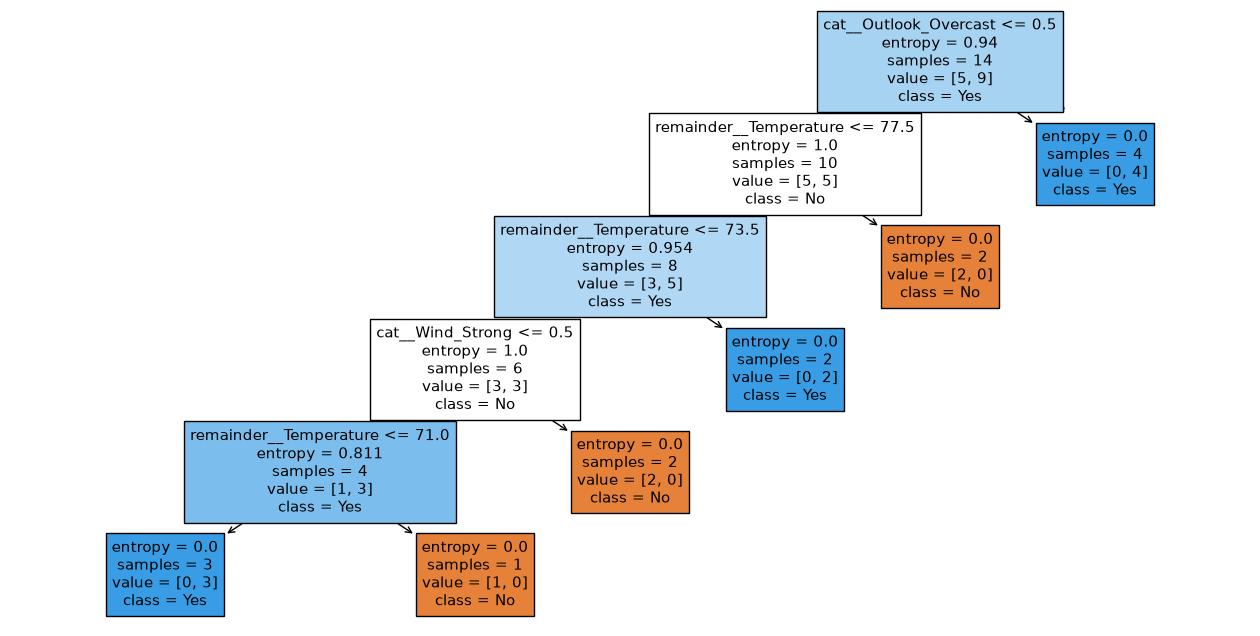

In [135]:
encoder = model.named_steps[
    "preprocessor"
]

classifier = model.named_steps[
    "classifier"
]

feature_names = encoder.get_feature_names_out()

plt.figure(
    figsize=(16, 8)
)

plot_tree(
    classifier,
    feature_names=feature_names,
    class_names=classifier.classes_,
    filled=True
)

plt.show()

#### 2. Write a program to demonstrate the working of the decision tree based CART algorithms using ```scikit-learn``` library. Use an following data set (Q. No 1 under Questions) for building the decision tree and apply this knowledge to classify a new sample. Compare with and without using ```scikit-learn``` library, also the results. The dataset has three attributes: Outlook (Sunny, Overcast, Rainy), Temperature, Humidity and Wind (Weak, Strong). The target attribute is Play Tennis (Yes/No).

In [136]:
df = pd.read_csv("tennis.csv")
df.head()

,Outlook,Temperature,Humidity,Wind,PlayTennis
0,Sunny,85,85,Weak,No
1,Sunny,80,90,Strong,No
2,Overcast,83,78,Weak,Yes
3,Rain,70,96,Weak,Yes
4,Rain,68,80,Weak,Yes


##### CART without ```scikit-learn```

In [137]:
def gini(df, target="PlayTennis"):
    counts = df["PlayTennis"].value_counts()
    total = len(df)

    impurity = 1

    for count in counts:
        p = count / total
        impurity -= p ** 2

    return impurity

In [138]:
gini(df)

0.4591836734693877

In [139]:
def weighted_gini(left, right):
    total = len(left) + len(right)

    return (
        len(left) / total * gini(left)
        +
        len(right) / total * gini(right)
    )

In [140]:
def best_split_numerical(df, attribute):
    values = sorted(
        df[attribute].unique()
    )

    best_gini = float("inf")
    best_threshold = None

    for i in range(len(values) - 1):

        threshold = (
            values[i] + values[i + 1]
        ) / 2

        left = df[
            df[attribute] <= threshold
        ]

        right = df[
            df[attribute] > threshold
        ]

        if len(left) == 0 or len(right) == 0:
            continue

        split_gini = weighted_gini(
            left,
            right
        )

        if split_gini < best_gini:

            best_gini = split_gini
            best_threshold = threshold

    return best_gini, best_threshold

In [141]:
def best_split_categorical(df, attribute):
    best_gini = float("inf")
    best_value = None

    for value in df[attribute].unique():
        left = df[df[attribute] == value]
        right = df[df[attribute] != value]

        if len(left) == 0 or len(right) == 0:
            continue

        split_gini = weighted_gini(left, right)

        if split_gini < best_gini:
            best_gini = split_gini
            best_value = value

    return best_gini, best_value

In [142]:
attributes = [
    "Outlook",
    "Temperature",
    "Humidity",
    "Wind"
]

attributes_numerical = [
    "Temperature",
    "Humidity"
]

In [143]:
def cart_split(df):
    best_attribute = None
    best_value = None
    best_gini = float("inf")
    best_type = None

    for attribute in attributes:

        if attribute in attributes_numerical:
            split_gini, threshold = best_split_numerical(df, attribute)

            if split_gini < best_gini:
                best_gini = split_gini
                best_attribute = attribute
                best_value = threshold
                best_type = "numeric"

        else:
            split_gini, value = best_split_categorical(df, attribute)

            if split_gini < best_gini:
                best_gini = split_gini
                best_attribute = attribute
                best_value = value
                best_type = "categorical"

    return best_attribute, best_value, best_gini, best_type

In [144]:
def majority_class(df, target="PlayTennis"):
    return df[target].value_counts().idxmax()

In [145]:
def cart(df, depth=0, max_depth=10, target="PlayTennis"):
    if len(df[target].unique()) == 1:
        return df[target].iloc[0]

    if depth >= max_depth:
        return majority_class(df)

    attribute, value, split_gini, split_type = cart_split(df)

    if attribute is None:
        return majority_class(df)

    if split_gini >= gini(df):
        return majority_class(df)

    if split_type == "numeric":
        left = df[df[attribute] <= value]
        right = df[df[attribute] > value]

    else:
        left = df[df[attribute] == value]
        right = df[df[attribute] != value]

    if len(left) == 0 or len(right) == 0:
        return majority_class(df)

    tree = {
        "attribute": attribute,
        "value": value,
        "type": split_type
    }

    tree["left"] = cart(
        left,
        depth + 1,
        max_depth
    )

    tree["right"] = cart(
        right,
        depth + 1,
        max_depth
    )

    return tree

In [146]:
tree = cart(df)
tree

{'attribute': 'Outlook',
 'value': 'Overcast',
 'type': 'categorical',
 'left': 'Yes',
 'right': {'attribute': 'Temperature',
  'value': np.float64(77.5),
  'type': 'numeric',
  'left': {'attribute': 'Temperature',
   'value': np.float64(66.5),
   'type': 'numeric',
   'left': 'No',
   'right': {'attribute': 'Temperature',
    'value': np.float64(70.5),
    'type': 'numeric',
    'left': 'Yes',
    'right': {'attribute': 'Temperature',
     'value': np.float64(73.5),
     'type': 'numeric',
     'left': 'No',
     'right': 'Yes'}}},
  'right': 'No'}}

In [147]:
def predict_cart(tree, sample):
    if not isinstance(tree, dict):
        return tree

    attribute = tree["attribute"]
    value = tree["value"]

    if tree["type"] == "numeric":
        if sample[attribute] <= value:
            return predict_cart(
                tree["left"],
                sample
            )

        else:
            return predict_cart(
                tree["right"],
                sample
            )

    else:
        if sample[attribute] == value:
            return predict_cart(
                tree["left"],
                sample
            )

        else:
            return predict_cart(
                tree["right"],
                sample
            )

In [148]:
manual_prediction = predict_cart(tree, new_sample)
print(f"Prediction (Manual CART): {manual_prediction}")

Prediction (Manual CART): No


#### CART using ```scikit-learn```

In [149]:
X = df[
    [
        "Outlook",
        "Temperature",
        "Humidity",
        "Wind"
    ]
]

y = df["PlayTennis"]

In [150]:
categorical_features = [
    "Outlook",
    "Wind"
]

numerical_features = [
    "Temperature",
    "Humidity"
]

In [151]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ],
    remainder="passthrough"
)

In [152]:
cart_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),

        (
            "classifier",
            DecisionTreeClassifier(
                criterion="gini",
                random_state=0
            )
        )
    ]
)

cart_model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['Outlook','Temperature','Humidity','Wind']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not 

In [153]:
new_sample_df = pd.DataFrame([new_sample])
new_sample_df

,Outlook,Temperature,Humidity,Wind
0,Sunny,72,90,Weak


In [154]:
sklearn_prediction = cart_model.predict(new_sample_df)[0]
print(f"Prediction (sklearn CART): {sklearn_prediction}")

Prediction (sklearn CART): No


In [155]:
feature_names = cart_model.named_steps[
    "preprocessor"
].get_feature_names_out()

feature_names

array(['cat__Outlook_Overcast', 'cat__Outlook_Rain', 'cat__Outlook_Sunny',
       'cat__Wind_Strong', 'cat__Wind_Weak', 'remainder__Temperature',
       'remainder__Humidity'], dtype=object)

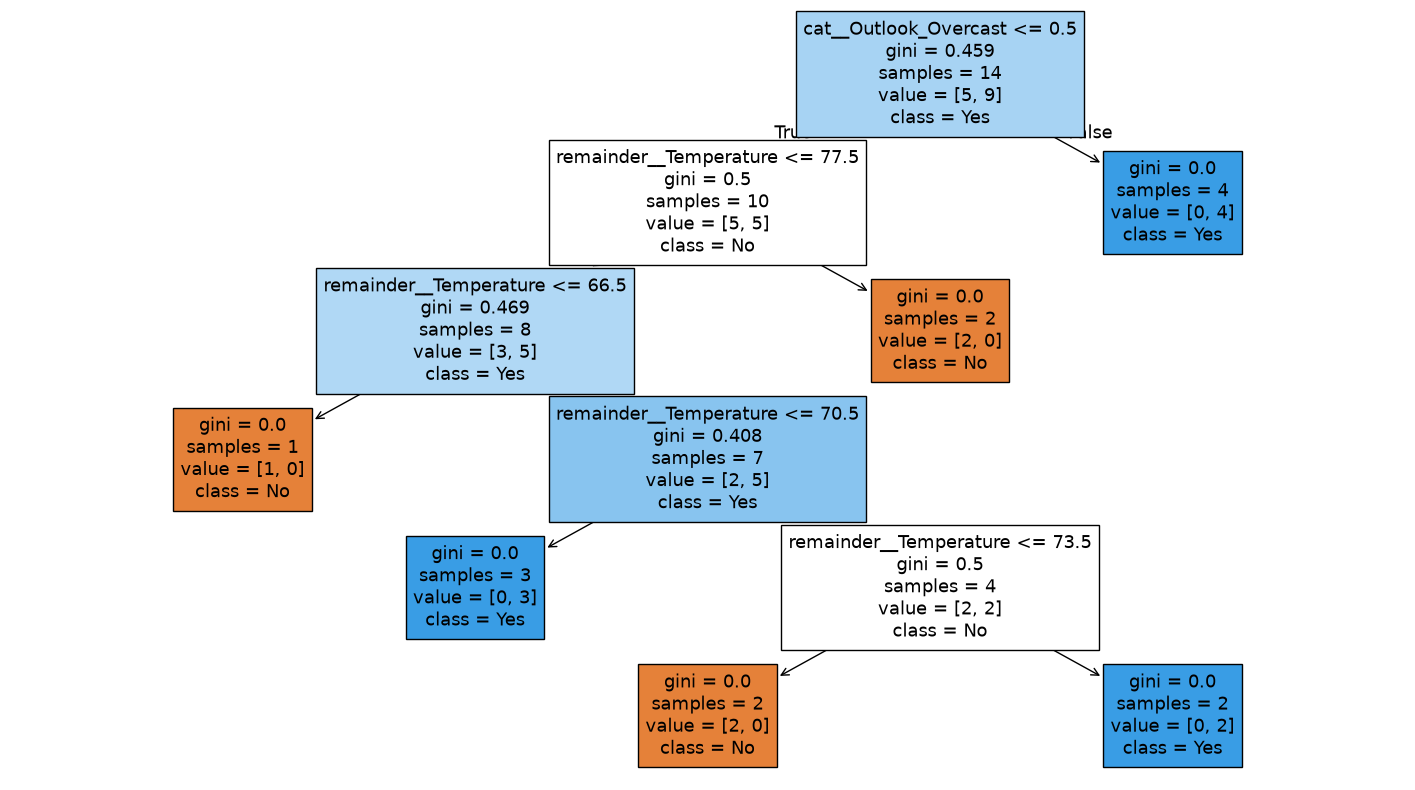

In [156]:
classifier = cart_model.named_steps[
    "classifier"
]

plt.figure(
    figsize=(18, 10)
)

plot_tree(
    classifier,
    feature_names=feature_names,
    class_names=classifier.classes_,
    filled=True
)

plt.show()